# Web APIs 第二天：DOM 事件基础

## 0. 本课内容与资料

本课是 JavaScript 第 07 篇，主题是 DOM 事件基础。学习主线按讲义展开：事件监听（绑定）→ 事件类型 → 事件对象 → 环境对象 `this` → 回调函数 → 综合案例。

主资料来自[用户提供的百度网盘分享](https://pan.baidu.com/s/1MxueOHXGQtmE-ypRq1kELA?pwd=9987)，提取码 `9987`，位置为 `2.web APIs / 资料 / web APIs第二天 / 01-PPT / web APIs第二天.pdf`。讲义共 42 页，已逐页读取公开预览，下面的教学图从原讲义页面裁切并内嵌到 Notebook。

代码示例使用[同课公开练习副本](https://github.com/wukaihang/pink-javascript/tree/main/2.Web%20APIs/day2)。除明确标为“整理示例”的片段外，下面 15 份完整 HTML 代码均来自该公开副本，保留原变量、缩进、注释和启用状态；讲义转录、整理示例与局部修正另行注明。网盘原 Markdown、课堂代码、测试题和作业正文尚未取得，未把公开副本当作网盘原文件。

本课的共同结构是：先找到事件源，再写事件类型，最后把要执行的函数交给浏览器。事件发生后，浏览器才调用这个函数；写在 `addEventListener` 里的函数不会在绑定时立即执行。

## 1. 事件监听（绑定）

### 1.1 事件是什么，监听解决什么问题

事件是程序运行时发生的动作或事情，例如用户单击按钮、鼠标经过菜单。事件监听就是让程序检测事件是否产生，一旦触发就立即调用处理函数，也叫绑定事件或注册事件。

事件监听有三个要素：

| 要素 | 含义 | 示例 |
| --- | --- | --- |
| 事件源 | 哪个 DOM 元素被触发 | `button` |
| 事件类型 | 用什么方式触发 | `click`、`mouseenter` |
| 事件处理函数 | 触发后要做什么 | 弹出提示、切换样式 |

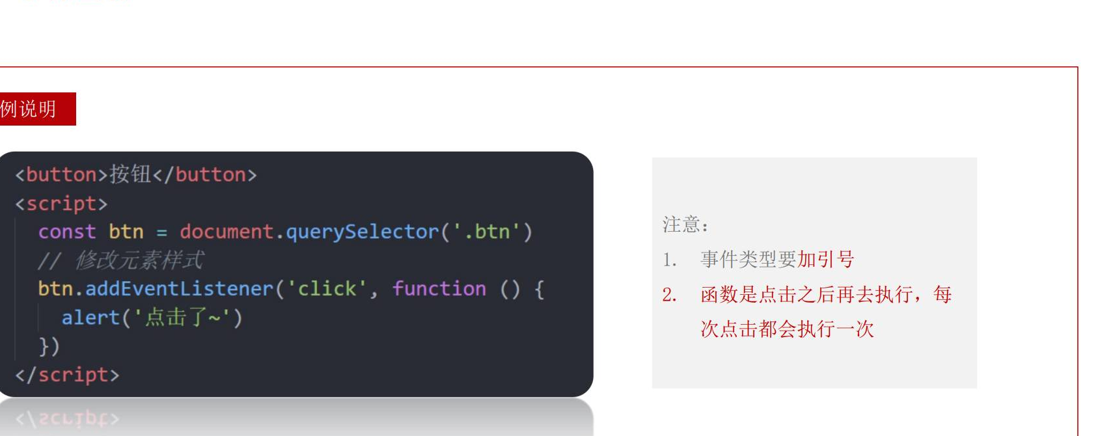

讲义截图使用 `.btn` 选择器，但图中的按钮没有写 `class="btn"`，直接照抄会取不到元素。下一小节的公开练习使用 `document.querySelector('button')`，与自己的 HTML 对应；也可以给按钮补上 `btn` 类。

### 1.2 `addEventListener` 的基本写法

事件类型要写成字符串。回调函数只在点击发生后执行，每点击一次执行一次。

公开练习副本原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <button>点击</button>
  <script>
    // 需求：点击按钮，弹出一个对话框
    // 1. 事件源 按钮
    let btn = document.querySelector('button')
    // 2. 事件类型 点击按钮
    // 3. 事件处理函数 弹出对话框
    btn.addEventListener('click', function () {
      alert('你点击了按钮')
    })

    // btn.onclick = () => {
    //   alert('你点击了按钮')
    // }
  </script>
</body>

</html>
```

`onclick` 也能绑定事件，但同一个元素的 `on事件` 属性容易被后一次赋值覆盖；`addEventListener` 可以在同一个元素上绑定多个处理函数，也有更多事件特性，是课程推荐的写法。原代码中注释掉的 `onclick` 保持注释状态。

### 1.3 案例：点击关闭京东顶部广告

需求是点击关闭按钮后隐藏顶部广告。分析时先区分“点击的是谁”和“要隐藏的是谁”：点击的是关闭按钮，关闭的是它的父盒子。把父盒子的 `style.display` 改成 `none` 即可隐藏，改成 `block` 可以显示。

分别取得关闭按钮和整个广告盒子，给按钮绑定 `click`，在回调里隐藏广告盒子。下面是**按讲义需求整理的最小示例**，公开副本缺少这个案例的原文件；文字广告用来代替课件里的横幅图：

```html
<!DOCTYPE html>
<html lang="zh-CN">
<head>
  <meta charset="UTF-8">
  <title>点击关闭顶部广告</title>
  <style>
    .ad { padding: 20px; background: #e8f3f4; }
  </style>
</head>
<body>
  <div class="ad">
    顶部广告
    <button class="close" type="button">关闭</button>
  </div>
  <script>
    const close = document.querySelector('.close')
    const ad = document.querySelector('.ad')
    close.addEventListener('click', function () {
      ad.style.display = 'none'
    })
  </script>
</body>
</html>
```

打开页面时能看到广告；点击关闭后整个 `.ad` 不再占据布局空间。只把按钮设为 `display: none` 会留下广告内容，不能完成需求。

如果按钮和广告盒子结构固定，也可以在回调里通过 `this.parentNode` 找到父盒子再隐藏；先把事件源和要操作的节点分清楚，选择直接保存盒子引用或使用 `parentNode` 都可以。

### 1.4 案例：随机点名

业务顺序：

1. 点击“开始”，用定时器快速从数组中取一个随机下标，并把姓名显示到页面。
2. 点击“结束”，清除定时器，再删除当前抽中的数组元素。
3. 数组只剩一个元素时，在“开始”业务中同时禁用两个按钮，因为最后一个不再需要继续抽取。

核心是 `setInterval` 负责快速展示，`clearInterval` 负责停止展示。公开练习副本原代码如下：

```html
<!DOCTYPE html>
<html lang="en">

<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Document</title>
    <style>
        * {
            margin: 0;
            padding: 0;
        }

        h2 {
            text-align: center;
        }

        .box {
            width: 600px;
            margin: 50px auto;
            display: flex;
            font-size: 25px;
            line-height: 40px;
        }

        .qs {

            width: 450px;
            height: 40px;
            color: red;

        }

        .btns {
            text-align: center;
        }

        .btns button {
            width: 120px;
            height: 35px;
            margin: 0 50px;
        }
    </style>
</head>

<body>
    <h2>随机点名</h2>
    <div class="box">
        <span>名字是：</span>
        <div class="qs">这里显示姓名</div>
    </div>
    <div class="btns">
        <button class="start">开始</button>
        <button class="end">结束</button>
    </div>

    <script>
        // 数据数组
        const arr = ['马超', '黄忠', '赵云', '关羽', '张飞']
        let timerId = 0
        let random = 0
        // 业务1.开始按钮模块
        const qs = document.querySelector('.qs')
        // 1.1 获取开始按钮对象 
        const start = document.querySelector('.start')
        // 1.2 添加点击事件
        start.addEventListener('click', function () {
            timerId = setInterval(function () {
                // 随机数
                random = Math.floor(Math.random() * arr.length)
                // console.log(arr[random])
                // 显示姓名
                qs.innerHTML = arr[random]
            }, 35)

            // 如果只剩一个元素，禁用开始按钮
            if (arr.length === 1) {
                start.disabled = true
                end.disabled = true
                // start.disabled = end.disabled = true
            }
        })

        // 业务2.结束按钮模块
        // 2.1 获取结束按钮对象
        const end = document.querySelector('.end')
        // 2.2 添加点击事件
        end.addEventListener('click', function () {
            clearInterval(timerId)
            // 结束后删除当前抽取的那个数组元素 
            arr.splice(random, 1)
            console.log(arr)
        })

    </script>
</body>

</html>
```

原练习保留了课程当时的写法：重复点击“开始”会创建多个定时器，点击“结束”前没有先判断是否真的开始，最后一个元素禁用按钮时也没有清除仍在运行的定时器。理解案例时先掌握讲义的业务流程；如果要把它用于正式页面，应额外保证只有一个定时器、结束前有有效状态，并在最后一个名字时清理定时器。

`random` 要声明在两个回调外面，因为“结束”也需要知道最后展示的是哪个下标。`splice(random, 1)` 删除一人以后，下次必须按新的 `arr.length` 生成随机下标。按“开始 → 等名字滚动 → 结束”的顺序验证，数组少一人，页面停留在刚抽中的名字；再次开始后不会再抽到这个人。

### 1.5 拓展阅读：事件监听版本

讲义按 DOM 级别介绍事件监听方式。`L` 是 `level`，表示级别。

| 级别 | 本课关注的内容 |
| --- | --- |
| DOM L0 | `元素.onclick = function () {}` 这样的属性赋值方式 |
| DOM L1 | DOM 级别 1 于 1998 年 10 月 1 日成为 W3C 推荐标准 |
| DOM L2 | 使用 `addEventListener` 注册事件 |
| DOM L3 | 在 DOM2 事件基础上重新定义并增加一些事件类型 |

同一属性重复赋值时后者覆盖前者；多个不同函数通过 `addEventListener('click', ...)` 注册时都能响应点击。这里是课程的版本介绍，不要求把所有历史级别当作不同的练习写法。

## 2. 事件类型

### 2.1 鼠标、焦点、键盘和输入事件

讲义把常见事件按触发方式分组：

| 类型 | 事件 | 触发时机 |
| --- | --- | --- |
| 鼠标事件 | `click` | 鼠标点击 |
| 鼠标事件 | `mouseenter` | 鼠标进入元素 |
| 鼠标事件 | `mouseleave` | 鼠标离开元素 |
| 焦点事件 | `focus` | 表单获得光标 |
| 焦点事件 | `blur` | 表单失去光标 |
| 键盘事件 | `keydown` | 键盘按下 |
| 键盘事件 | `keyup` | 键盘抬起 |
| 文本事件 | `input` | 表单内容发生输入 |

`mouseenter` 和 `mouseleave` 只在进入、离开当前元素时触发，适合本课的颜色变化练习。公开练习副本原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    div {
      width: 100px;
      height: 100px;
      background: pink;
    }
  </style>
</head>

<body>
  <div></div>
  <input type="text">
  <script>
    const div = document.querySelector('div')
    // 鼠标经过
    div.addEventListener('mouseenter', function () {
      div.style.background = 'skyblue'
    })
    // 鼠标离开
    div.addEventListener('mouseleave', function () {
      div.style.background = 'pink'
    })
  </script>
</body>

</html>
```

### 2.2 案例：轮播图点击切换与自动播放

轮播图的分析来自讲义：

1. 点击右按钮让下标 `i` 加一，达到数组长度时回到 `0`。
2. 点击左按钮让 `i` 减一，小于 `0` 时回到最后一张。
3. 图片、标题、底部背景色和小圆点都要跟着同一个 `i` 同步变化。
4. 鼠标经过轮播图暂停定时器，鼠标离开时先清除旧定时器，再重新开启一个定时器。

公开练习副本原代码：

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8" />
  <meta http-equiv="X-UA-Compatible" content="IE=edge" />
  <meta name="viewport" content="width=device-width, initial-scale=1.0" />
  <title>轮播图点击切换</title>
  <style>
    * {
      box-sizing: border-box;
    }

    .slider {
      width: 560px;
      height: 400px;
      overflow: hidden;
    }

    .slider-wrapper {
      width: 100%;
      height: 320px;
    }

    .slider-wrapper img {
      width: 100%;
      height: 100%;
      display: block;
    }

    .slider-footer {
      height: 80px;
      background-color: rgb(100, 67, 68);
      padding: 12px 12px 0 12px;
      position: relative;
    }

    .slider-footer .toggle {
      position: absolute;
      right: 0;
      top: 12px;
      display: flex;
    }

    .slider-footer .toggle button {
      margin-right: 12px;
      width: 28px;
      height: 28px;
      appearance: none;
      border: none;
      background: rgba(255, 255, 255, 0.1);
      color: #fff;
      border-radius: 4px;
      cursor: pointer;
    }

    .slider-footer .toggle button:hover {
      background: rgba(255, 255, 255, 0.2);
    }

    .slider-footer p {
      margin: 0;
      color: #fff;
      font-size: 18px;
      margin-bottom: 10px;
    }

    .slider-indicator {
      margin: 0;
      padding: 0;
      list-style: none;
      display: flex;
      align-items: center;
    }

    .slider-indicator li {
      width: 8px;
      height: 8px;
      margin: 4px;
      border-radius: 50%;
      background: #fff;
      opacity: 0.4;
      cursor: pointer;
    }

    .slider-indicator li.active {
      width: 12px;
      height: 12px;
      opacity: 1;
    }
  </style>
</head>

<body>
  <div class="slider">
    <div class="slider-wrapper">
      <img src="./images/slider01.jpg" alt="" />
    </div>
    <div class="slider-footer">
      <p>对人类来说会不会太超前了？</p>
      <ul class="slider-indicator">
        <li class="active"></li>
        <li></li>
        <li></li>
        <li></li>
        <li></li>
        <li></li>
        <li></li>
        <li></li>
      </ul>
      <div class="toggle">
        <button class="prev">&lt;</button>
        <button class="next">&gt;</button>
      </div>
    </div>
  </div>
  <script>
    // 1. 初始数据
    const sliderData = [
      { url: './images/slider01.jpg', title: '对人类来说会不会太超前了？', color: 'rgb(100, 67, 68)' },
      { url: './images/slider02.jpg', title: '开启剑与雪的黑暗传说！', color: 'rgb(43, 35, 26)' },
      { url: './images/slider03.jpg', title: '真正的jo厨出现了！', color: 'rgb(36, 31, 33)' },
      { url: './images/slider04.jpg', title: '李玉刚：让世界通过B站看到东方大国文化', color: 'rgb(139, 98, 66)' },
      { url: './images/slider05.jpg', title: '快来分享你的寒假日常吧~', color: 'rgb(67, 90, 92)' },
      { url: './images/slider06.jpg', title: '哔哩哔哩小年YEAH', color: 'rgb(166, 131, 143)' },
      { url: './images/slider07.jpg', title: '一站式解决你的电脑配置问题！！！', color: 'rgb(53, 29, 25)' },
      { url: './images/slider08.jpg', title: '谁不想和小猫咪贴贴呢！', color: 'rgb(99, 72, 114)' },
    ]

    const img = document.querySelector('.slider-wrapper img')
    const p = document.querySelector('.slider-footer p')
    const footer = document.querySelector('.slider-footer')
    // 业务1：右侧按钮点击
    const next = document.querySelector('.next')
    let i = 0
    next.addEventListener('click', function () {
      // console.log('右侧按钮点击')
      i++
      i >= sliderData.length ? i = 0 : null
      toggle()
    })

    // 业务2：左侧按钮点击
    const prev = document.querySelector('.prev')
    prev.addEventListener('click', function () {
      // console.log('左侧按钮点击')
      i--
      i < 0 ? i = sliderData.length - 1 : null
      toggle()
    })

    // 声明一个渲染的函数作为复用
    function toggle() {
      img.src = sliderData[i].url
      p.textContent = sliderData[i].title
      footer.style.backgroundColor = sliderData[i].color
      document.querySelector('.slider-indicator li.active').classList.remove('active')
      document.querySelector(`.slider-indicator li:nth-child(${i + 1})`).classList.add('active')
    }

    // 业务3：自动播放
    let timerId = setInterval(() => {
      next.click()
    }, 1000)

    // 业务4：鼠标经过暂停自动播放
    const slider = document.querySelector('.slider')
    slider.addEventListener('mouseenter', function () {
      clearInterval(timerId)
    })

    // 业务5：鼠标离开继续自动播放
    slider.addEventListener('mouseleave', function () {
      // 先关再开
      clearInterval(timerId)
      timerId = setInterval(() => {
        next.click()
      }, 1000)
    })


  </script>
</body>

</html>
```

代码用 `next.click()` 复用右按钮的切换逻辑，所以自动播放与手动点击走同一条业务路径。小圆点只有样式和当前项切换，本文件没有给小圆点绑定点击事件；要实现点击小圆点，还需要增加对应的事件监听。

`toggle()` 集中更新四处状态：图片 `src`、标题 `textContent`、背景 `backgroundColor`、圆点 `active`。数组下标从 `0` 开始，CSS `nth-child` 从 `1` 开始，因此圆点用 `${i + 1}`。默认 HTML 已经对应第 1 张图，并且恰好有一个 `active`，清除旧圆点时才能查到元素。

验证左按钮时，从第 1 张应回到第 8 张；再点右按钮应回到第 1 张。鼠标停在轮播图上应停止自动变化，移开后每秒前进一张，图片、标题、背景与圆点保持对应。`images` 文件夹需要与 HTML 位于同一级，否则图片无法显示。

### 2.3 案例：小米搜索框

需求是输入框获得焦点时显示下拉列表并加上橙色边框，失去焦点时隐藏列表并移除样式类。初始化时列表默认隐藏，焦点和失焦分别做相反操作。

公开练习副本原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <input type="text">
  <script>
    const input = document.querySelector('input')
    input.addEventListener('focus', function () {
      console.log('获得焦点')
    })
    input.addEventListener('blur', function () {
      console.log('失去焦点')
    })
  </script>
</body>

</html>
```

```html
<!DOCTYPE html>
<html lang="en">

<head>
    <meta charset="UTF-8">
    <meta http-equiv="X-UA-Compatible" content="IE=edge">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Document</title>
    <style>
        * {
            margin: 0;
            padding: 0;
            box-sizing: border-box;
        }

        ul {

            list-style: none;
        }

        .mi {
            position: relative;
            width: 223px;
            margin: 100px auto;
        }

        .mi input {
            width: 223px;
            height: 48px;
            padding: 0 10px;
            font-size: 14px;
            line-height: 48px;
            border: 1px solid #e0e0e0;
            outline: none;
        }

        .mi .search {
            border: 1px solid #ff6700;
        }

        .result-list {
            position: absolute;
            left: 0;
            top: 48px;
            width: 223px;
            border: 1px solid #ff6700;
            border-top: 0;
            background: #fff;
            display: none;
        }

        .result-list a {
            display: block;
            padding: 6px 15px;
            font-size: 12px;
            color: #424242;
            text-decoration: none;
        }

        .result-list a:hover {
            background-color: #eee;
        }
    </style>

</head>

<body>
    <div class="mi">
        <input type="search" placeholder="小米笔记本">
        <ul class="result-list">
            <li><a href="#">全部商品</a></li>
            <li><a href="#">小米11</a></li>
            <li><a href="#">小米10S</a></li>
            <li><a href="#">小米笔记本</a></li>
            <li><a href="#">小米手机</a></li>
            <li><a href="#">黑鲨4</a></li>
            <li><a href="#">空调</a></li>
        </ul>
    </div>
    <script>
        // const input = document.querySelector('input')
        // 属性选择器
        const input = document.querySelector('[type=search]')
        const resultList = document.querySelector('.result-list')
        input.addEventListener('focus', function () {
            resultList.style.display = 'block'
            input.classList.add('search')
        })
        input.addEventListener('blur', function () {
            resultList.style.display = 'none'
            input.classList.remove('search')
        })


    </script>
</body>

</html>
```

这里没有搜索接口，列表只是用来演示 `focus`、`blur`、`classList.add` 和 `classList.remove` 的配合。

### 2.4 键盘事件和输入事件

`keydown` 在按下键盘时触发，`keyup` 在松开时触发；用户修改输入框内容时使用 `input`。公开练习副本中 `keydown`、`keyup` 的监听保持注释，启用的是 `input`，输入内容后在控制台打印 `input.value`。

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <input type="text">
  <script>
    // 键盘事件
    const input = document.querySelector('input')
    // input.addEventListener('keydown', function (e) {
    //   console.log('键盘按下')
    // })
    // input.addEventListener('keyup', function (e) {
    //   console.log('键盘弹起')
    // })

    // 用户输入文本事件
    input.addEventListener('input', function (e) {
      console.log(input.value)
      // console.log(e.target.value)
    })
  </script>
</body>

</html>
```

除了 JavaScript 事件，CSS 的 `:focus` 也能在获得焦点时改变样式。例如下面的输入框通过过渡效果从 `200px` 放大到 `300px`，没有使用 JavaScript。

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    input {
      width: 200px;
      transition: all 0.3s;
    }

    input:focus {
      width: 300px;
    }
  </style>
</head>

<body>
  <input type="text">
</body>

</html>
```

### 2.5 案例：评论字数统计

需求是用户输入文字时显示当前字数。分析步骤：

1. 给文本域绑定 `input` 事件。
2. 每次事件触发时读取 `textarea.value.length`。
3. 把得到的长度写入计数区域。

文本域设置 `maxlength="200"`，所以页面提示使用 `0/200字` 这样的格式。焦点时显示计数，失焦时隐藏计数。

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>评论回车发布</title>
  <style>
    .wrapper {
      min-width: 400px;
      max-width: 800px;
      display: flex;
      justify-content: flex-end;
    }

    .avatar {
      width: 48px;
      height: 48px;
      border-radius: 50%;
      overflow: hidden;
      background: url(./images/avatar.jpg) no-repeat center / cover;
      margin-right: 20px;
    }

    .wrapper textarea {
      outline: none;
      border-color: transparent;
      resize: none;
      background: #f5f5f5;
      border-radius: 4px;
      flex: 1;
      padding: 10px;
      transition: all 0.5s;
      height: 30px;
    }

    .wrapper textarea:focus {
      border-color: #e4e4e4;
      background: #fff;
      height: 50px;
    }

    .wrapper button {
      background: #00aeec;
      color: #fff;
      border: none;
      border-radius: 4px;
      margin-left: 10px;
      width: 70px;
      cursor: pointer;
    }

    .wrapper .total {
      margin-right: 80px;
      color: #999;
      margin-top: 5px;
      opacity: 0;
      transition: all 0.5s;
    }

    .list {
      min-width: 400px;
      max-width: 800px;
      display: flex;
    }

    .list .item {
      width: 100%;
      display: flex;
    }

    .list .item .info {
      flex: 1;
      border-bottom: 1px dashed #e4e4e4;
      padding-bottom: 10px;
    }

    .list .item p {
      margin: 0;
    }

    .list .item .name {
      color: #FB7299;
      font-size: 14px;
      font-weight: bold;
    }

    .list .item .text {
      color: #333;
      padding: 10px 0;
    }

    .list .item .time {
      color: #999;
      font-size: 12px;
    }
  </style>
</head>

<body>
  <div class="wrapper">
    <i class="avatar"></i>
    <textarea id="tx" placeholder="发一条友善的评论" rows="2" maxlength="200"></textarea>
    <button>发布</button>
  </div>
  <div class="wrapper">
    <span class="total">0/200字</span>
  </div>
  <div class="list">
    <div class="item" style="display: none;">
      <i class="avatar"></i>
      <div class="info">
        <p class="name">清风徐来</p>
        <p class="text">大家都辛苦啦，感谢各位大大的努力，能圆满完成真是太好了[笑哭][支持]</p>
        <p class="time">2022-10-10 20:29:21</p>
      </div>
    </div>
  </div>

  <script>
    // 当文本域获得了焦点，让 total 显示出来
    const tx = document.querySelector('#tx')
    const total = document.querySelector('.total')
    tx.addEventListener('focus', function () {
      total.style.opacity = 1
    })
    // 当文本域失去了焦点，让 total 隐藏起来
    tx.addEventListener('blur', function () {
      total.style.opacity = 0
    })
    // 检测用户输入
    tx.addEventListener('input', function () {
      total.innerHTML = `${tx.value.length}/200字`
    })

  </script>
</body>

</html>
```

输入或粘贴文字时计数随之变化，删除文字也会更新。输入中文 `你好` 应显示 `2/200字`；失焦只隐藏计数，不会清空输入。这里 `.value.length` 是字符串长度，复杂表情可能占多个长度单位；原练习采用这一计数方式。本文件的留言 `.item` 默认隐藏，还没有实现发布功能。

## 3. 事件对象

### 3.1 获取事件对象

事件对象也是一个对象，保存事件触发时的相关信息，例如鼠标点在什么位置、按下了哪一个键。它位于事件绑定回调函数的第一个参数，常命名为 `event`、`ev` 或 `e`。

本节原代码在下一小节给出，重点先记住：`e` 是浏览器调用处理函数时传进来的参数，不需要自己创建事件对象。

事件对象常用于判断用户按下的键（例如回车发布信息），或判断鼠标点击的位置和元素，再执行对应操作。

### 3.2 常用属性

| 属性 | 含义 |
| --- | --- |
| `type` | 当前事件类型，如 `click`、`keyup` |
| `clientX` / `clientY` | 光标相对于浏览器可见窗口左上角的位置 |
| `offsetX` / `offsetY` | 光标相对于当前 DOM 元素左上角的位置 |
| `key` | 用户按下的键盘键的值 |

讲义提示不要再使用 `keyCode` 判断键值，键盘案例使用 `e.key`。公开练习副本原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <button>点击</button>
  <input type="text">
  <script>
    const btn = document.querySelector('button')
    // 事件对象 e
    // 事件对象是事件处理函数的第一个参数
    // 事件对象中包含了事件相关的信息
    btn.addEventListener('click', function (e) {
      console.log(e)
      // 事件类型
      console.log(e.type)
      // 事件发生时，鼠标距离浏览器窗口的位置
      console.log(e.clientX, e.clientY)
      // 事件发生时，鼠标距离事件源元素(按钮)的位置
      console.log(e.offsetX, e.offsetY)
    })

    const input = document.querySelector('input')
    input.addEventListener('keyup', function (e) {
      // 事件发生时，用户按下的键
      // console.log(e.key)
      if (e.key === 'Enter') {
        console.log('用户按下了回车键')
      }
    })
  </script>
</body>

</html>
```

打开控制台后点击按钮，能看到事件对象、`click` 类型与两组坐标；在输入框中松开回车会输出“用户按下了回车键”。讲义将 `offsetX/Y` 简化为相对当前元素，准确地说它们相对事件目标元素的内边距边缘；本例只有按钮文字，事件目标就是按钮。

### 3.3 `trim()`：只去掉字符串两端空白

评论不能只有空格，先用 `trim()` 判断去掉两端空白后是否仍有内容。它返回一个新字符串，不改变原字符串，也不去掉文本中间的空格。公开练习副本原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <textarea name="" id="" cols="30" rows="10"></textarea>
  <script>
    const str = '   你好啊，我是清风徐来   '
    console.log(str)
    // 去掉字符串 两端 的空格
    console.log(str.trim())

    const tx = document.querySelector('textarea')
    tx.addEventListener('keyup', function (e) {
      // console.log(tx.value)
      // 去掉字符串 两端 的空格
      console.log(tx.value.trim())
    })
  </script>
</body>

</html>
```

控制台先打印带空格的 `str`，再打印处理后的字符串。文本域的 `keyup` 只是打印 `tx.value.trim()`，没有把结果写回 `tx.value`。例如 `'  你 好  '.trim()` 得到 `'你 好'`，中间的空格仍保留。

### 3.4 案例：按下回车发布评论

需求是按下回车后发布信息。`keydown` 或 `keyup` 都可以监听，先判断 `e.key === 'Enter'`，再让留言区域显示并把文本域内容渲染进去。

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>评论回车发布</title>
  <style>
    .wrapper {
      min-width: 400px;
      max-width: 800px;
      display: flex;
      justify-content: flex-end;
    }

    .avatar {
      width: 48px;
      height: 48px;
      border-radius: 50%;
      overflow: hidden;
      background: url(./images/avatar.jpg) no-repeat center / cover;
      margin-right: 20px;
    }

    .wrapper textarea {
      outline: none;
      border-color: transparent;
      resize: none;
      background: #f5f5f5;
      border-radius: 4px;
      flex: 1;
      padding: 10px;
      transition: all 0.5s;
      height: 30px;
    }

    .wrapper textarea:focus {
      border-color: #e4e4e4;
      background: #fff;
      height: 50px;
    }

    .wrapper button {
      background: #00aeec;
      color: #fff;
      border: none;
      border-radius: 4px;
      margin-left: 10px;
      width: 70px;
      cursor: pointer;
    }

    .wrapper .total {
      margin-right: 80px;
      color: #999;
      margin-top: 5px;
      opacity: 0;
      transition: all 0.5s;
    }

    .list {
      min-width: 400px;
      max-width: 800px;
      display: flex;
    }

    .list .item {
      width: 100%;
      display: flex;
    }

    .list .item .info {
      flex: 1;
      border-bottom: 1px dashed #e4e4e4;
      padding-bottom: 10px;
    }

    .list .item p {
      margin: 0;
    }

    .list .item .name {
      color: #FB7299;
      font-size: 14px;
      font-weight: bold;
    }

    .list .item .text {
      color: #333;
      padding: 10px 0;
    }

    .list .item .time {
      color: #999;
      font-size: 12px;
    }
  </style>
</head>

<body>
  <div class="wrapper">
    <i class="avatar"></i>
    <textarea id="tx" placeholder="发一条友善的评论" rows="2" maxlength="200"></textarea>
    <button>发布</button>
  </div>
  <div class="wrapper">
    <span class="total">0/200字</span>
  </div>
  <div class="list">
    <div class="item" style="display: none;">
      <i class="avatar"></i>
      <div class="info">
        <p class="name">清风徐来</p>
        <p class="text">大家都辛苦啦，感谢各位大大的努力，能圆满完成真是太好了[笑哭][支持]</p>
        <p class="time">2022-10-10 20:29:21</p>
      </div>
    </div>
  </div>

  <script>
    // 当文本域获得了焦点，让 total 显示出来
    const tx = document.querySelector('#tx')
    const total = document.querySelector('.total')
    const item = document.querySelector('.item')
    const text = item.querySelector('.text')
    tx.addEventListener('focus', function () {
      total.style.opacity = 1
    })
    // 当文本域失去了焦点，让 total 隐藏起来
    tx.addEventListener('blur', function () {
      total.style.opacity = 0
    })
    // 检测用户输入
    tx.addEventListener('input', function () {
      total.innerHTML = `${tx.value.length}/200字`
    })
    // 当用户按下了回车键，发布评论
    tx.addEventListener('keyup', function (e) {
      // 只有按下的是回车键才会触发
      if (e.key === 'Enter') {
        // console.log('用户按下了回车键')
        if (tx.value.trim()) {
          item.style.display = 'block'
          // console.log(tx.value)
          // 将用户输入的内容，显示到评论内容中
          text.innerHTML = tx.value
        }
        // 按下回车时清空文本域中的内容
        tx.value = ''
        // 按下回车时，将字符统计复原
        total.innerHTML = '0/200字'
      }
    })
  </script>
</body>

</html>
```

这份原练习有几个需要看清的边界：

- `trim()` 只用于判断输入是否为空白；显示时仍使用原始 `tx.value`。
- 回车发生在 `keyup` 中时，换行行为已经发生，代码没有阻止默认换行。
- 练习只更新页面中已有的一个 `.item`，不是不断生成多条评论。
- “发布”按钮没有绑定点击事件，发布入口是回车。
- 原代码使用 `innerHTML` 写入用户输入；如果要求把输入当作纯文本，应改用 `textContent`，避免把输入解析成 HTML。

**局部修正示例**：只替换写入评论的这一行，其余流程不变。

```javascript
text.textContent = tx.value
```

输入“你好”后按回车，已有留言盒子显示新内容，文本域清空，计数重置为 `0/200字`；输入全空白后按回车，原留言不更新，但输入仍被清空。再次发布会替换这一条留言，页面不会新增第二条；清空输入后也要手动更新计数，因为程序赋值不会自动触发 `input` 事件。

## 4. 环境对象 `this`

### 4.1 先理解运行环境

环境对象指函数内部特殊的变量 `this`，它代表函数运行时所处的环境。课程给出的粗略判断规则是“谁调用，`this` 就是谁”。直接调用普通函数时，可以理解为 `window.函数()`，因此非严格模式下 `this` 指向 `window`；作为事件监听器的普通函数执行时，`this` 指向绑定事件的元素。

公开练习副本原代码：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <button>点击</button>
  <script>
    // 每个函数里面都有this 环境对象 this代表当前函数运行时所处的环境
    // 普通函数里面this指向window
    // function fn() {
    //   console.log(this)
    // }
    // window.fn()

    const btn = document.querySelector('button')
    btn.addEventListener('click', function () {
      console.log(this)
      this.style.color = 'red'
    })
  </script>
</body>

</html>
```

本节只整理课程范围内的普通函数和事件回调。箭头函数没有自己的 `this`，其指向规则属于后续更完整的函数内容，不把它混入这里的粗略判断。

原代码里的“普通函数里面 this 指向 window”需要放在浏览器经典脚本、非严格模式、直接调用这个条件下理解；严格模式直接调用普通函数时 `this` 是 `undefined`。当前启用的是事件监听器，所以点击按钮后按钮文字变红，`this` 等于当前绑定监听器的按钮；前面的普通函数例子仍然是注释，不会执行。

## 5. 回调函数

### 5.1 定义

如果把函数 A 作为参数传给函数 B，函数 A 就叫回调函数。回调函数本质上仍然是函数，只是被当作参数交给另一个函数，在合适的时机由另一个函数调用。事件监听器、定时器回调都属于本课常见场景。

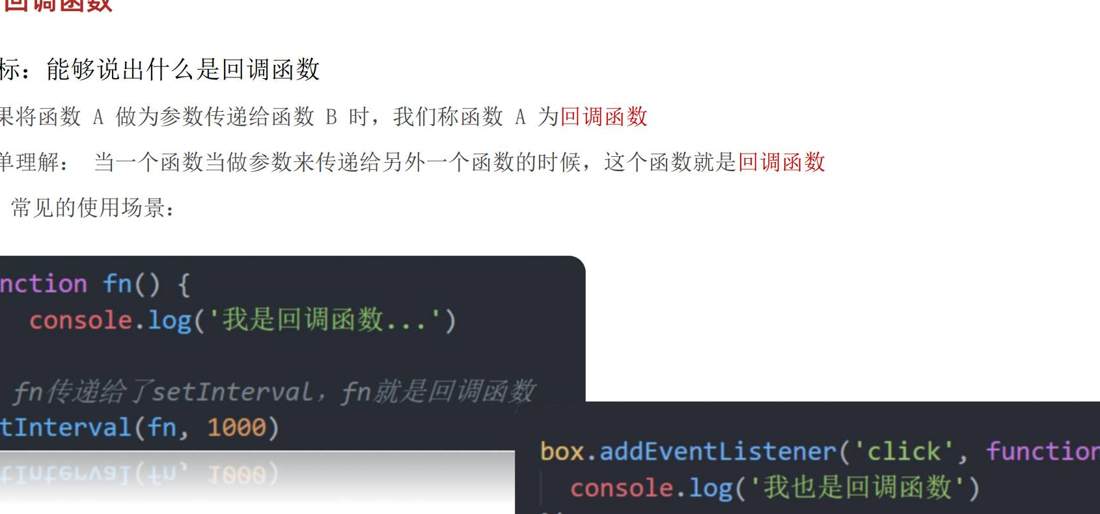

公开练习副本原文件保留了课程说明注释：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>

  <script>
    // 回调函数
    // 一个函数A作为参数传递到另一个函数B中，在另一个函数B中被调用，函数A就是回调函数
    // 回调函数的本质还是函数，只不过把它当做参数使用
    // 回调函数的作用是在某个事件发生后，执行一段代码
    // 回调函数的优势是可以将代码的执行延迟到某个事件发生后再执行
  </script>
</body>

</html>
```

常见形式可以概括为：

```javascript
function fn() {
  console.log('我是回调函数...')
}

// fn传递给了setInterval，fn就是回调函数
setInterval(fn, 1000)
```

上面的代码按讲义第 36 页图中示例转录。事件回调则常用匿名函数，以下是该页另一个示例的整理形式（先取得页面中的 `.box`）：

```javascript
const box = document.querySelector('.box')
box.addEventListener('click', function () {
  console.log('我也是回调函数')
})
```

这里 `fn` 作为参数传给 `setInterval`，由定时器在每次时间到达时调用。回调函数不等于“必然异步”，是否延后取决于调用它的 API；本课中的事件和定时器会在相应触发时调用。

## 6. 综合案例：Tab 栏切换

### 6.1 需求与分析

需求是鼠标经过不同选项卡时，底部显示对应内容。讲义把核心归纳为“类名切换”和“排他思想”：当前元素添加 `active`，其余元素移除 `active`，并且当前类只能有一个。

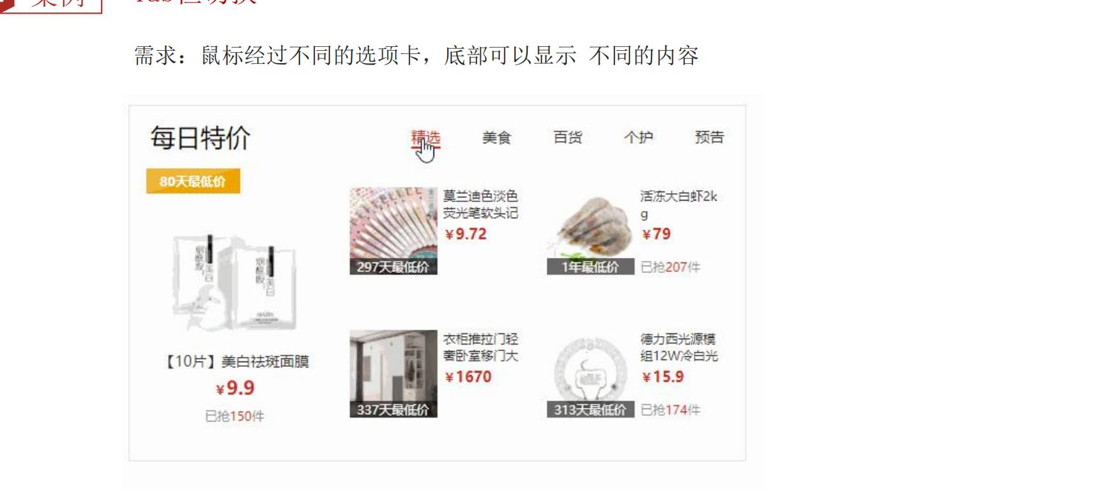

实现步骤：

1. 获取五个导航链接，循环给每个链接绑定 `mouseenter`。
2. 事件触发时先循环移除所有链接的 `active`，再给当前链接添加 `active`。
3. 移除当前显示内容的 `active`，通过 `i + 1` 找到对应的 `.item` 并添加 `active`。

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8" />
  <meta http-equiv="X-UA-Compatible" content="IE=edge" />
  <meta name="viewport" content="width=device-width, initial-scale=1.0" />
  <title>tab栏切换</title>
  <style>
    * {
      margin: 0;
      padding: 0;
    }

    .tab {
      width: 590px;
      height: 340px;
      margin: 20px;
      border: 1px solid #e4e4e4;
    }

    .tab-nav {
      width: 100%;
      height: 60px;
      line-height: 60px;
      display: flex;
      justify-content: space-between;
    }

    .tab-nav h3 {
      font-size: 24px;
      font-weight: normal;
      margin-left: 20px;
    }

    .tab-nav ul {
      list-style: none;
      display: flex;
      justify-content: flex-end;
    }

    .tab-nav ul li {
      margin: 0 20px;
      font-size: 14px;
    }

    .tab-nav ul li a {
      text-decoration: none;
      border-bottom: 2px solid transparent;
      color: #333;
    }

    .tab-nav ul li a.active {
      border-color: #e1251b;
      color: #e1251b;
    }

    .tab-content {
      padding: 0 16px;
    }

    .tab-content .item {
      display: none;
    }

    .tab-content .item.active {
      display: block;
    }
  </style>
</head>

<body>
  <div class="tab">
    <div class="tab-nav">
      <h3>每日特价</h3>
      <ul>
        <li><a class="active" href="javascript:;">精选</a></li>
        <li><a href="javascript:;">美食</a></li>
        <li><a href="javascript:;">百货</a></li>
        <li><a href="javascript:;">个护</a></li>
        <li><a href="javascript:;">预告</a></li>
      </ul>
    </div>
    <div class="tab-content">
      <div class="item active"><img src="./images/tab00.png" alt="" /></div>
      <div class="item"><img src="./images/tab01.png" alt="" /></div>
      <div class="item"><img src="./images/tab02.png" alt="" /></div>
      <div class="item"><img src="./images/tab03.png" alt="" /></div>
      <div class="item"><img src="./images/tab04.png" alt="" /></div>
    </div>
  </div>
  <script>
    // 1. 给五个链接绑定鼠标经过事件
    // 1.1 获取所有链接
    const links = document.querySelectorAll('.tab-nav ul li a')
    for (let i = 0; i < links.length; i++) {
      links[i].addEventListener('mouseenter', function () {
        // 1.2 给所有链接移除active类名 （排他思想）
        for (let j = 0; j < links.length; j++) {
          links[j].classList.remove('active')
        }
        // 1.3 给当前链接添加active类名 this指向当前链接links[i]
        this.classList.add('active')

        // 下面五个大盒子一一对应 .item
        // 排他思想
        // 1.4 给所有大盒子移除active类名
        document.querySelector('.tab-content .active').classList.remove('active')
        // 1.5 给当前大盒子添加active类名
        document.querySelector(`.tab-content .item:nth-child(${i + 1})`).classList.add('active')
      })
    }

  </script>
</body>

</html>
```

本案例使用鼠标经过切换，事件委托和点击切换不在本课实现范围内。`this` 在这里指当前触发事件的链接，`i` 用来把导航链接和内容盒子一一对应起来。

注意原注释“给所有大盒子移除 active 类名”下面实际只查找并移除一个当前活动盒子的类名。由于初始化和每次切换都保证只有一个活动项，这样就足够；如果 HTML 没有任何活动内容，`querySelector('.tab-content .active')` 会返回 `null`。`let i` 让每次循环绑定的回调保留各自的下标。

依次经过五个导航项，导航和内容应分别始终只有一个 `active`，且两者位置对应；原代码使用 `images/tab00.png` 到 `tab04.png` 展示内容图，配套 `images` 文件夹同样要与 HTML 放在一起。

## 7. 今日作业

讲义最后安排：整理当天笔记，完成测试题，练习随机点名和评论发布案例，练习 Tab 栏切换三遍并完成作业。练习重点是把事件源、事件类型、事件处理函数三要素写完整，并能在事件对象中取到 `key` 或坐标等信息。